# STEP 2 - Coarse Overview

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
import os
import sys

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']

Loading satellites/
Aspect ratio:  5
Ratio of rotational diffusion:  0.06769699908603415
Ratio of orthogonal diffusion:  0.7664558871581453


# View 1

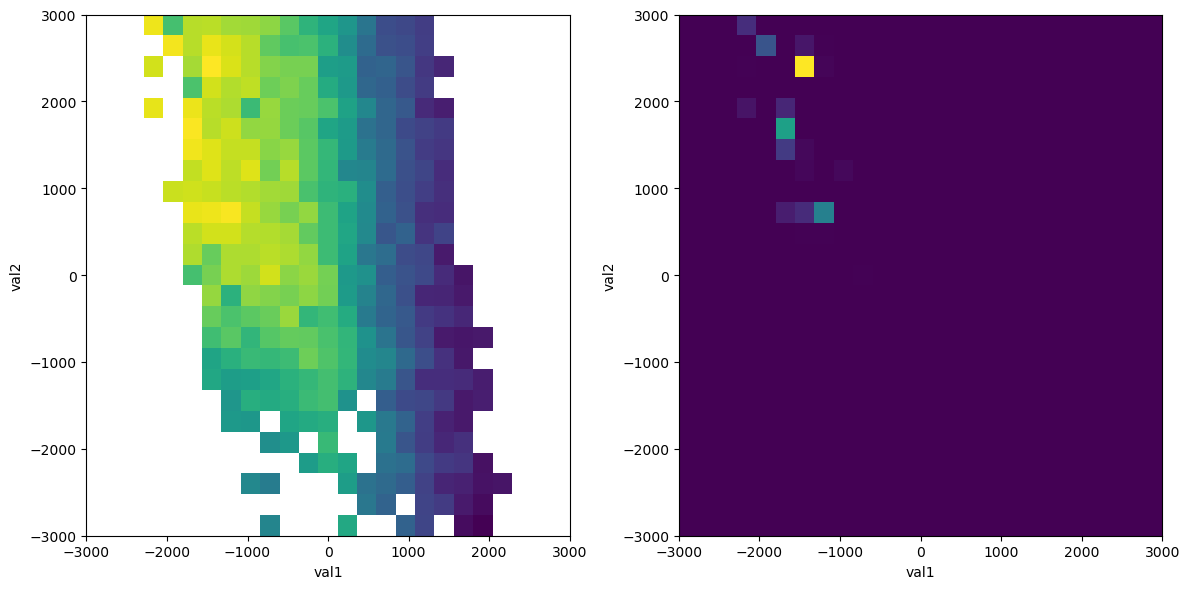

In [ ]:
n_trajectories = 10
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

scale = 3000
val1_min = -scale
val1_max = scale
val2_min = -scale
val2_max = scale

resolution = 25

alpha_grid = np.linspace(val1_min, val1_max, resolution)
k_grid = np.linspace(val2_min, val2_max, resolution)

ALPHA_GRID, K_GRID = np.meshgrid(alpha_grid, k_grid)
shape_chunk = ALPHA_GRID.shape
ALPHA_GRID = ALPHA_GRID.flatten()
K_GRID = K_GRID.flatten()

params = np.stack((ALPHA_GRID, K_GRID), axis=1)

max_angle = 45 * np.pi / 180

''' Particle Filter '''

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10,
                                   clip_parameters=scale,
                                   )

#logl -= np.abs(params).sum(axis=1) / 10 # Exponential prior
logl = logl.reshape(shape_chunk)

P = np.exp((logl-logl.max())/100)
P /= np.sum(P)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 99
idx = np.argmax(CDF > (100 - perc) / 10000000)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(logl, extent=(val1_min, val1_max, val2_min, val2_max), origin='lower', aspect='auto')
plt.xlabel('val1')
plt.ylabel('val2')
plt.subplot(1, 2, 2)
plt.imshow(P, extent=(val1_min, val1_max, val2_min, val2_max), origin='lower', aspect='auto')
#plt.contour(alpha_grid, k_grid, P, levels=[P_flat[idx]], linestyles='--')
#plt.plot(ALPHA, K, 'ro', label='Ground Truth')
plt.xlabel('val1')
plt.ylabel('val2')
plt.savefig('particle1.png', dpi=300)
plt.tight_layout()
plt.show()